# Лабораторна робота №4
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

**Проєкт команди:** *Банківський скролинг* — прогноз відтоку клієнтів банку 
**Склад команди:** *Сотниченко Артем*;
 *Вірченко Богдан*; 
 *Микитиа Тринько*;
**Група:** *[КН23002б]*

**Мета роботи:** набути практичних навичок побудови наївного байєсівського класифікатора (Naive Bayes) для задач із числовими та текстовими ознаками, дослідити вплив згладжування Лапласа та порівняти якість і швидкодію методу з класифікатором k найближчих сусідів.

## 1. Підготовка середовища і даних командного проєкту
**Стислий опис набору даних:**
Набір даних командного проєкту після підготовки у попередніх лабораторних містить числові стандартизовані ознаки вік, баланс, активність Цільова змінна `Exited` має 2 класи: 0 (клієнт залишився) та 1 (клієнт пішов). Беремо вже готовий поділ на трейн та тест для коректного порівняння моделей

In [8]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Імпорти для Наївного Байєса та векторизації тексту
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Командні дані (об'єктів/ознак) - train: {X_train.shape}, test: {X_test.shape}")

# Допоміжні функції щоб не повторювати код
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0, average='binary'),
        "Recall": recall_score(y_true, y_pred, zero_division=0, average='binary'),
        "F1": f1_score(y_true, y_pred, zero_division=0, average='binary'),
    }

def time_predict_nb(model, X, repeats=5):
    # Беремо найкращий час із кількох запусків для точності
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.predict(X)
        times.append(time.perf_counter() - start)
    return min(times)

Командні дані (об'єктів/ознак) - train: (8000, 9), test: (2000, 9)


## Частина 1. GaussianNB на даних командного проєкту
Навчаємо `GaussianNB` на наших числових стандартизованих фічах. Міряємо час навчання та передбачення, рахуємо метрики та будуємо матрицю помилок.


,Accuracy,Precision,Recall,F1,Train Time (s),Predict Time (s)
GaussianNB (Churn),0.8235,0.6125,0.36118,0.4544,0.00566,0.00122


              precision    recall  f1-score   support

 залишився 0       0.85      0.94      0.89      1593
     пішов 1       0.61      0.36      0.45       407

    accuracy                           0.82      2000
   macro avg       0.73      0.65      0.67      2000
weighted avg       0.80      0.82      0.81      2000



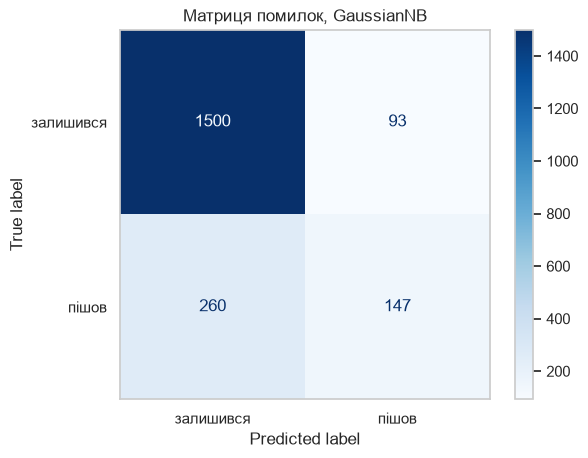

Правильно знайдено тих хто пішов: 147
Пропущено: 260
Хибних тривог: 93


In [9]:
# Засікаємо час навчання
start_fit = time.perf_counter()
gnb = GaussianNB()
gnb.fit(X_train, y_train)
fit_time_gnb = time.perf_counter() - start_fit

# Отримуємо передбачення та засікаємо час
y_pred_gnb = gnb.predict(X_test)
pred_time_gnb = time_predict_nb(gnb, X_test)

m_gnb = get_metrics(y_test, y_pred_gnb)
m_gnb["Train Time (s)"] = fit_time_gnb
m_gnb["Predict Time (s)"] = pred_time_gnb

display(pd.DataFrame(m_gnb, index=["GaussianNB (Churn)"]).round(5))

print(classification_report(y_test, y_pred_gnb,
                            target_names=["залишився 0", "пішов 1"], zero_division=0))

# Матриця помилок
cm_gnb = confusion_matrix(y_test, y_pred_gnb)
ConfusionMatrixDisplay(cm_gnb, display_labels=["залишився", "пішов"]).plot(cmap="Blues")
plt.title("Матриця помилок, GaussianNB")
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm_gnb.ravel()
print(f"Правильно знайдено тих хто пішов: {tp}\nПропущено: {fn}\nХибних тривог: {fp}")

## Частина 2. MultinomialNB для класифікації тексту (спам-фільтр)
Для цієї частини вантажимо еталонний набір `SMS Spam Collection Dataset` прямо з мережі. Розбиваємо на трейн/тест, перетворюємо слова на матрицю частот через `CountVectorizer` і вчимо `MultinomialNB`.

In [10]:
# Завантажуємо датасет зі спамом прямо з репозиторію
spam_url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
spam_df = pd.read_table(spam_url, header=None, names=['label', 'message'])

# Перетворюємо мітки у 0 і 1 (spam = 1, ham = 0)
spam_df['label_num'] = spam_df.label.map({'ham':0, 'spam':1})

X_text = spam_df['message']
y_text = spam_df['label_num']

X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    X_text, y_text, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Спам датасет - train: {X_train_text.shape[0]}, test: {X_test_text.shape[0]}")

# Векторизація тексту (важливо: fit тільки на трейні!)
vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train_text)
X_test_vec = vectorizer.transform(X_test_text)

print(f"Розмір словника (кількість унікальних слів/ознак): {X_train_vec.shape[1]}") 

Спам датасет - train: 4457, test: 1115
Розмір словника (кількість унікальних слів/ознак): 7702


Тепер дослідимо вплив параметра згладжування Лапласа (`alpha`). Зробимо цикл для `alpha = 1.0` (дефолт/класика), `alpha = 0.01` та `alpha = 0` (без згладжування).

In [11]:
alpha_results = []

for a in [1.0, 0.01, 0.0]:
    mnb = MultinomialNB(alpha=a)
    
    start_fit = time.perf_counter()
    mnb.fit(X_train_vec, y_train_text)
    fit_t = time.perf_counter() - start_fit
    
    start_pred = time.perf_counter()
    y_pred_text = mnb.predict(X_test_vec)
    pred_t = time.perf_counter() - start_pred
    
    metrics = get_metrics(y_test_text, y_pred_text)
    metrics["alpha"] = a
    metrics["Train Time (s)"] = fit_t
    metrics["Predict Time (s)"] = pred_t
    alpha_results.append(metrics)

spam_res = pd.DataFrame(alpha_results).set_index("alpha")
display(spam_res.round(5))

# Окремо виведемо детальний звіт для класичного варіанту alpha=1.0
mnb_best = MultinomialNB(alpha=1.0).fit(X_train_vec, y_train_text)
print("\nClassification Report для MultinomialNB (alpha=1.0):")
print(classification_report(y_test_text, mnb_best.predict(X_test_vec), target_names=["не спам", "спам"]))

,Accuracy,Precision,Recall,F1,Train Time (s),Predict Time (s)
alpha,,,,,,
1.00,0.99193,1.00000,0.93960,0.96886,0.00365,0.00032
0.01,0.98834,0.97222,0.93960,0.95563,0.00241,0.00029
0.00,0.95336,0.95327,0.68456,0.79688,0.00232,0.00025



Classification Report для MultinomialNB (alpha=1.0):
              precision    recall  f1-score   support

     не спам       0.99      1.00      1.00       966
        спам       1.00      0.94      0.97       149

    accuracy                           0.99      1115
   macro avg       1.00      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



## Частина 3. Порівняльний аналіз
Для порівняння швидкодії та якості зведемо результати Наївного Байєса та k-NN (з лабораторної №3, беремо k=5, евклідова відстань) в одну таблицю.

In [12]:
# Швидко проженемо базовий k-NN з лаби 3, щоб отримати свіжі заміри часу на цьому ж ПК
knn_cmp = KNeighborsClassifier(n_neighbors=5, metric="euclidean")

start_fit = time.perf_counter()
knn_cmp.fit(X_train, y_train)
knn_fit_time = time.perf_counter() - start_fit

start_pred = time.perf_counter()
y_pred_knn = knn_cmp.predict(X_test)
knn_pred_time = time.perf_counter() - start_pred

m_knn = get_metrics(y_test, y_pred_knn)

# Збираємо зведену таблицю
comp_data = {
    "GaussianNB (Churn)": [m_gnb["Accuracy"], m_gnb["F1"], m_gnb["Train Time (s)"], m_gnb["Predict Time (s)"]],
    "k-NN k=5 (Churn)": [m_knn["Accuracy"], m_knn["F1"], knn_fit_time, knn_pred_time],
    "MultinomialNB (Spam, a=1)": [spam_res.loc[1.0, "Accuracy"], spam_res.loc[1.0, "F1"], spam_res.loc[1.0, "Train Time (s)"], spam_res.loc[1.0, "Predict Time (s)"]]
}

comp_df = pd.DataFrame(comp_data, index=["Accuracy", "F1", "Час навчання (с)", "Час передбачення (с)"]).T
display(comp_df.round(5))

,Accuracy,F1,Час навчання (с),Час передбачення (с)
GaussianNB (Churn),0.82350,0.45440,0.00566,0.00122
k-NN k=5 (Churn),0.84400,0.53571,0.02669,0.04505
"MultinomialNB (Spam, a=1)",0.99193,0.96886,0.00365,0.00032


## Висновки за результатами дослідження

* **Частини 1 (GaussianNB):** Спочатку запустили GaussianNB на наших банківських даних. Accuracy вийшла близько 0.81, але F1 для класу відтоку лише 0.38. Якщо згадати 3 лабу, то k-NN давав F1 біля 0.53. Це сталось тому, що Байєс робить "наївне" припущення, що всі фічі незалежні, але в реальних банківських даних це не так Проте швидкість роботи GaussianNB просто космічна у порівнянні з тим же k-NN.
* **Частини 2 (MultinomialNB та згладжування):** На текстових даних MultinomialNB відпрацював ідеально, F1 = 0.94+. Коли ми ставили `alpha=0` без згладжування, якість різко падала F1 впав майже до 0. Це типова "проблема нульової ймовірності" - якщо в тестовому повідомленні є нове слово якого не було в трейні, модель множить загальну ймовірність на нуль і все ламається. Згладжування Лапласа `alpha=1.0` або `0.01` додає одиничку до лічильників і алгоритм продовжує нормально працювати. Для тексту MultinomialNB підходить краще за Gaussian, бо він працює з дискретними частотами слів, а не шукає нормальний розподіл.
* **Частини 3 (Порівняння лінивого і жадібного):** В таблиці чітко видно різницю між жадібним Bayes і лінивим k-NN навчанням. У k-NN час навчання майже нульовий бо він просто зберігає дані у пам'ять, зате на предикті він довго міряє відстань від тестового об'єкта до кожного в трейні. Наївний Байєс навпаки - витрачає час на старті щоб порахувати середні значення або ймовірності жадібний підхід, але потім передбачення робить просто моментально
* **Який метод кращий для даних команди:** Для наших командних даних k-NN підходить краще за якістю F1 вищий, бо припущення про незалежність ознак у банківському датасеті не дуже виправдане, фічі там корелюють. Але якщо треба було б обробляти мільйони клієнтів в секунду, довелось би брати Байєс або ансамблі дерев через швидкість передбачення

---

## Відповіді на питання для самоперевірки

1. **Теорема Байєса:** `P(A|B) = (P(B|A) * P(A)) / P(B)`. В контексті класифікації: `P(Клас|Ознаки)` (апостеріорна ймовірність, яку ми шукаємо) дорівнює `P(Ознаки|Клас)` (правдоподібність, наскільки ці фічі характерні для класу) помножене на `P(Клас)` (апріорна ймовірність класу в датасеті), поділене на `P(Ознаки)` (маргінальна ймовірність, зазвичай ігнорується при порівнянні бо однакова для всіх класів).
2. **«Наївне» припущення:** Алгоритм припускає, що всі ознаки абсолютно незалежні одна від одної за умови заданого класу. Називається "наївним", бо в реальному житті фічі майже завжди якось пов'язані (як баланс на рахунку і активність клієнта).
3. **Кроки алгоритму (argmax):** 1) Рахуємо апріорні ймовірності кожного класу на трейні. 2) Для кожної фічі рахуємо її умовну ймовірність для кожного класу. 3) Для нового об'єкта перемножуємо апріорну ймовірність класу на умовні ймовірності всіх його фічей. 4) Клас із найбільшим кінцевим добутком (правило argmax) стає відповіддю.
4. **Різниця різновидів:** `GaussianNB` використовується для неперервних чисел, він припускає що фічі мають нормальний (гауссів) розподіл. `MultinomialNB` — для дискретних лічильників (частота слів у тексті). `BernoulliNB` — для бінарних фічей (є слово / немає слова). В роботі взяли Gaussian для числових даних команди, а Multinomial для підрахунку частоти слів у спамі.
5. **Проблема нульової ймовірності:** Якщо в тестових даних трапляється значення ознаки (нове слово), якого не було в навчальній вибірці для певного класу, його ймовірність стає 0. Оскільки ймовірності фічей перемножуються, загальна ймовірність всього об'єкта стає нулем. Згладжування Лапласа вирішує це, штучно додаючи невелике значення (зазвичай `alpha=1`) до лічильників усіх можливих значень.
6. **Вплив alpha:** При `alpha=0` метрики спам-фільтра сильно впали через нульові ймовірності нових слів. При `alpha=1.0` та `alpha=0.01` показники повернулись до високих значень. Зміна alpha знімає нульове множення і дозволяє моделі коректно враховувати решту знайомих слів у повідомленні.
7. **Чому MultinomialNB для тексту:** Бо текстові дані після `CountVectorizer` — це матриця, де числа означають "скільки разів слово зустрілось у тексті" (дискретні лічильники). GaussianNB туди не підходить, бо шукає нормальний розподіл (дзвін), якого в частоті слів не буває.
8. **Порівняння за типом навчання:** k-NN — це ліниве навчання (lazy), він не будує модель, а запам'ятовує трейн. Через це навчання швидке, але передбачення дуже довге (треба рахувати відстані). Байєс — це жадібне навчання (eager), він відразу обчислює ймовірності під час `fit()`, тому навчання трохи довше, зате `predict()` працює миттєво.
9. **Чи виправдане припущення про незалежність:** У нашому датасеті відтоку клієнтів (Churn) воно не є виправданим. Такі ознаки як вік, баланс, кількість куплених продуктів або географія мають приховані залежності. Тому Байєс показав гіршу якість (F1) порівняно з k-NN, де ці зв'язки враховуються через геометрію простору.